# The Network

In [1]:
import numpy as np 
import torch 
import matplotlib.pyplot as plt
from pathlib import Path
from rbergomi_nn.network import VolSurfaceMLP
from rbergomi_nn.dataset import SurfaceDataset
from rbergomi_nn.simulator import DTYPE, PARAMETER_NAMES

ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()
model = VolSurfaceMLP.load(ROOT / "models" / "vol_surface_mlp.pt")
ds = SurfaceDataset.load(ROOT / "data" / "surfaces.npz")
val, test = ds.subset("val"), ds.subset("test")
grid = ds.grid
labels = ["H", "eta", "rho", "xi0"]

print(model)
print("total params:", sum(p.numel() for p in model.parameters()))
print("theta range :", model.theta_lower.tolist(), model.theta_upper.tolist())

for name, p in model.layers.named_parameters():
    print(f"{name:12s} {tuple(p.shape)!s:10s} mean={p.mean():+.3f} std={p.std():.3f} "
          f"min={p.min():+.3f} max={p.max():+.3f}")

VolSurfaceMLP(
  (layers): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): SiLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): SiLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): SiLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): SiLU()
    (8): Linear(in_features=64, out_features=80, bias=True)
  )
)
total params: 18000
theta range : [0.05, 1.0, -0.9, 0.02] [0.4, 3.0, -0.2, 0.12]
0.weight     (64, 4)    mean=-0.033 std=0.325 min=-0.914 max=+0.690
0.bias       (64,)      mean=-0.012 std=0.244 min=-0.426 max=+0.455
2.weight     (64, 64)   mean=+0.003 std=0.110 min=-0.637 max=+0.795
2.bias       (64,)      mean=+0.016 std=0.070 min=-0.115 max=+0.139
4.weight     (64, 64)   mean=+0.003 std=0.105 min=-0.565 max=+0.425
4.bias       (64,)      mean=+0.007 std=0.076 min=-0.213 max=+0.154
6.weight     (64, 64)   mean=+0.005 std=0.105 min=-0.571 max=+0.513
6.bias       (64,)      mean=+0.002

(np.float64(-0.25), np.float64(5.25), np.float64(-3.85), np.float64(3.85))

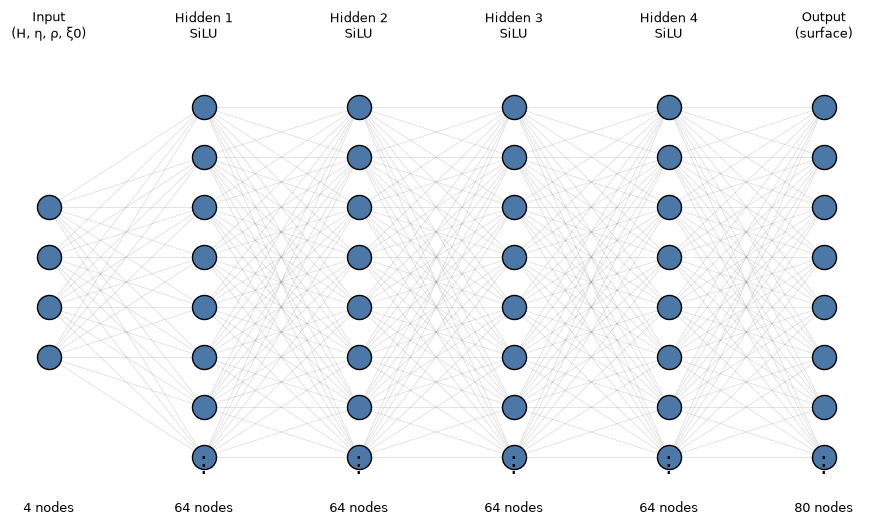

In [28]:
sizes = [4] + list(model.hidden_sizes) + [grid.size]      # [4, 64, 64, 64, 64, 80]
names = ["Input\n(H, η, ρ, ξ0)"] + [f"Hidden {i+1}\nSiLU" for i in range(len(model.hidden_sizes))] + ["Output\n(surface)"]
MAXN = 8                                             

fig, ax = plt.subplots(figsize=(11, 5))
pos = []
for x, n in enumerate(sizes):
    shown = min(n, MAXN)
    ys = [(shown - 1) / 2 - j for j in range(shown)]
    pos.append([(x, y) for y in ys])
    ax.scatter([x] * shown, ys, s=300, zorder=3, color="#4c78a8", edgecolor="k")
    ax.text(x, (MAXN / 2) + 0.8, names[x], ha="center", va="bottom", fontsize=9)
    ax.text(x, -(MAXN / 2) - 0.6, f"{n} nodes", ha="center", fontsize=9)
    if n > MAXN:
        ax.text(x, -(MAXN / 2) + 0.2, "⋮", ha="center", fontsize=16)
for a, b in zip(pos[:-1], pos[1:]):
    for (x0, y0) in a:
        for (x1, y1) in b:
            ax.plot([x0, x1], [y0, y1], color="gray", alpha=0.25, lw=0.6, zorder=1)
ax.axis("off")

### Weights

Matrices:
- rows = input weights
- columns = output weights

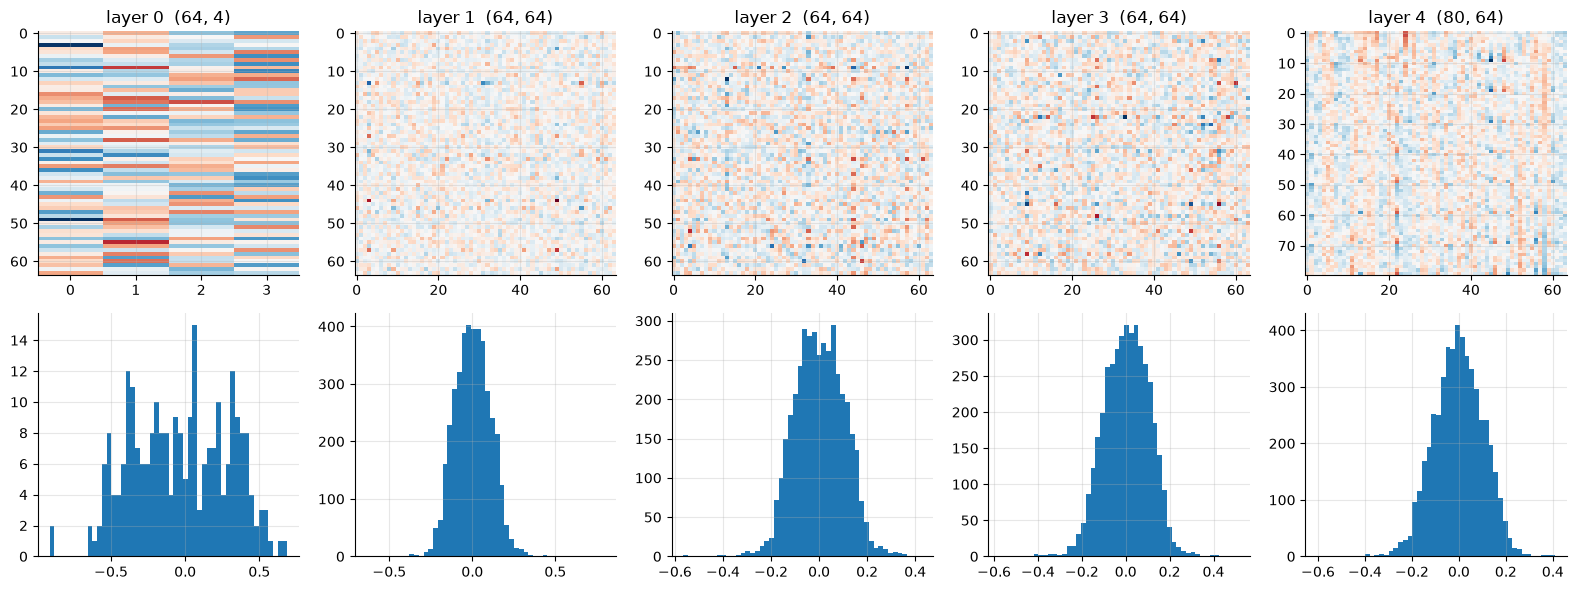

In [14]:
linears = [m for m in model.layers if isinstance(m, torch.nn.Linear)]
fig, axes = plt.subplots(2, len(linears), figsize=(3.2 * len(linears), 6))
for i, lin in enumerate(linears):
    W = lin.weight.detach().numpy()
    v = np.abs(W).max()
    axes[0, i].imshow(W, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
    axes[0, i].set_title(f"layer {i}  {W.shape}")
    axes[1, i].hist(W.ravel(), bins=50)
plt.tight_layout()

### Singular Values of the weights matrices

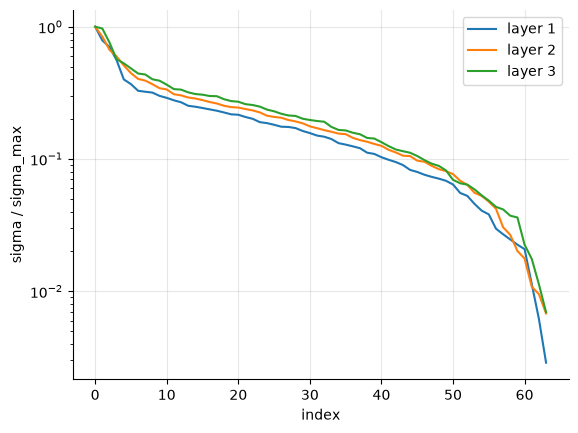

In [22]:
fig, ax = plt.subplots()
for i, lin in enumerate(linears[1:-1], start=1):  # square hidden layers
    s = torch.linalg.svdvals(lin.weight.detach()).numpy()
    ax.semilogy(s / s[0], label=f"layer {i}")
ax.set_xlabel("index"); ax.set_ylabel("sigma / sigma_max"); ax.legend()

### Jacobian: sensitivity map over the maturity×strike grid

max |analytic - autograd|: 8.881784197001252e-16


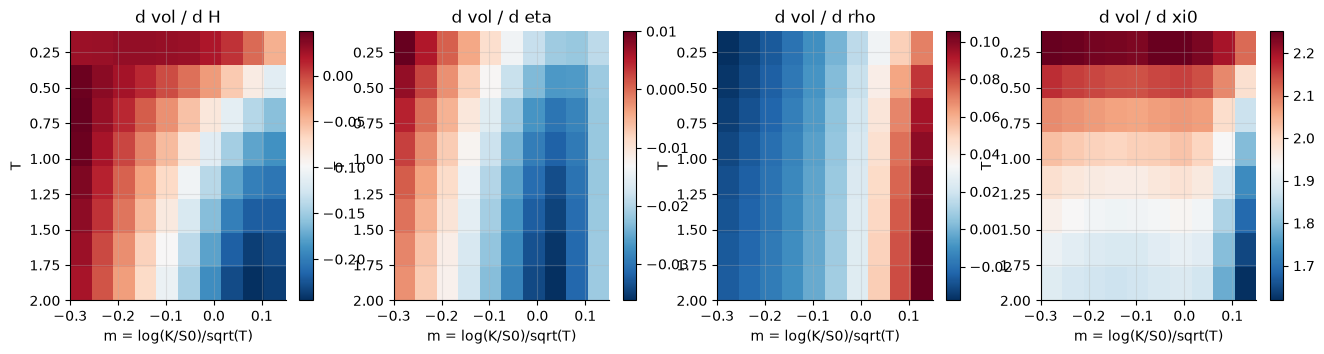

In [ ]:
theta0 = torch.tensor([0.12, 1.9, -0.7, 0.04], dtype=DTYPE)   # H, eta, rho, xi0
J = model.jacobian(theta0).numpy().reshape(*grid.shape, 4)    # (T, K, 4)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for k, ax in enumerate(axes):
    im = ax.imshow(J[..., k], aspect="auto", cmap="RdBu_r",
                   extent=[grid.scaled_moneyness[0], grid.scaled_moneyness[-1],
                           grid.maturities[-1], grid.maturities[0]])
    ax.set_title(f"d vol / d {labels[k]}"); ax.set_xlabel("m = log(K/S0)/sqrt(T)"); ax.set_ylabel("T")
    plt.colorbar(im, ax=ax)

# Check against autograd
J_ad = torch.autograd.functional.jacobian(model, theta0).numpy().reshape(*grid.shape, 4)
print("max |analytic - autograd|:", np.abs(J - J_ad).max())

###  First-layer sensitivity to each parameter

Text(0.5, 1.0, 'L2 norm of first-layer weights per input (inputs are scaled to [-1, 1])')

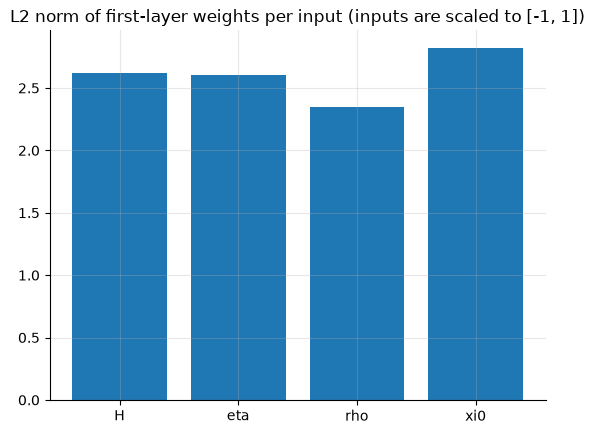

In [24]:
W0 = linears[0].weight.detach().numpy()          # (64, 4)
plt.bar(labels, np.linalg.norm(W0, axis=0))
plt.title("L2 norm of first-layer weights per input (inputs are scaled to [-1, 1])")

### Vol Smiles as $H$ varies

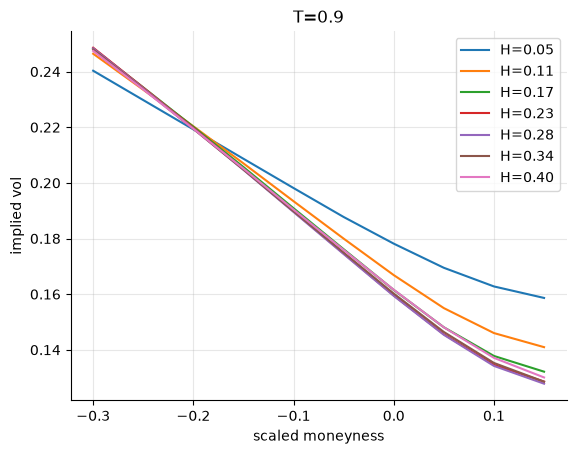

In [19]:
k = 0                                  # 0=H, 1=eta, 2=rho, 3=xi0
lo, hi = model.theta_lower[k].item(), model.theta_upper[k].item()
values = np.linspace(lo, hi, 7)
base = theta0.clone(); mat = 3         # maturity index

fig, ax = plt.subplots()
for v in values:
    t = base.clone(); t[k] = v
    with torch.no_grad():
        surf = model(t[None]).reshape(grid.shape)[mat]
    ax.plot(grid.scaled_moneyness, surf, label=f"{labels[k]}={v:.2f}")
ax.set_xlabel("scaled moneyness"); ax.set_ylabel("implied vol")
ax.set_title(f"T={grid.maturities[mat]}"); ax.legend()

### Error map

Text(0, 0.5, 'surface RMSE (vol pts)')

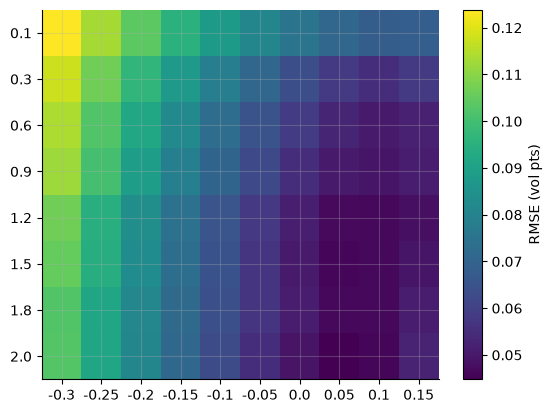

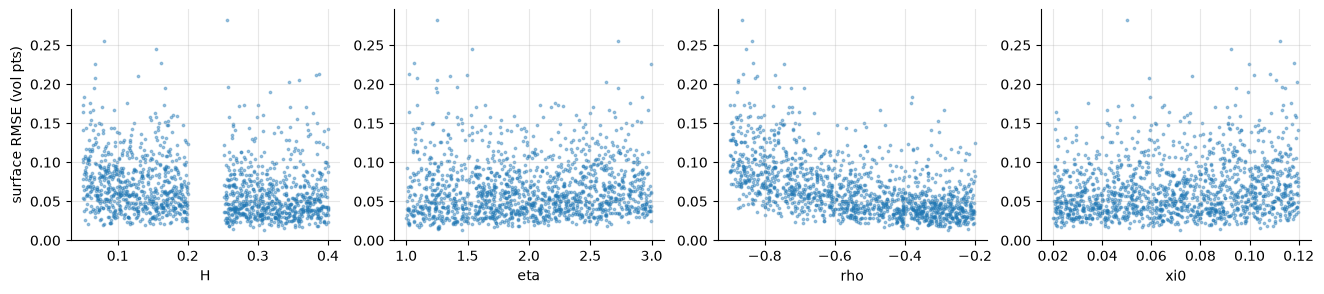

In [20]:
with torch.no_grad():
    pred = model(torch.as_tensor(test.theta, dtype=DTYPE)).numpy().reshape(test.implied_vol.shape)
err = 100 * (pred - test.implied_vol)                          # vol points

fig, ax = plt.subplots()
im = ax.imshow(np.sqrt((err ** 2).mean(0)), aspect="auto"); plt.colorbar(im, label="RMSE (vol pts)")
ax.set_xticks(range(len(grid.scaled_moneyness)), grid.scaled_moneyness)
ax.set_yticks(range(len(grid.maturities)), grid.maturities)

per_surface = np.sqrt((err ** 2).mean((1, 2)))
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for k, ax in enumerate(axes):
    ax.scatter(test.theta[:, k], per_surface, s=3, alpha=0.4); ax.set_xlabel(labels[k])
axes[0].set_ylabel("surface RMSE (vol pts)")